**Introduction** </n></n>

Instead of guessing, travelers get forecasted arrival hiccups through AeroDelay AI - a browser-accessible tool running predictive algorithms on live air travel information. Inputting departure point, target airport, scheduled day, and hour leads to estimated punctuality scores backed by contributing causes: sky conditions, terminal congestion, past patterns. Pulling feeds from public interfaces such as OpenSky Network plus Aviationstack handles aircraft movements; temperature, wind, precipitation come from OpenWeatherMap snapshots. Behind the scenes, earlier records train a decision-tree-heavy method (random forest approach using scikit-learn), sorting likelihoods into color-coded timelines and charts shown back to users. A hands-on approach to artificial intelligence takes shape here within flight operations, where combining information streams matters most. Information flows into systems designed to learn through repeated examples. Interfaces respond clearly because structure comes from Flask while React shapes what users see. Working together, these pieces form a cohesive whole grounded in real-world use.

### Background and Scope </n></n>

Not every wait at the gate stays small—delays often grow into broader problems: added operating expenses for carriers, disrupted connections, and knock-on adjustments in crew and aircraft positioning across the network. In the U.S., public on-time performance reporting tracks how often flights are delayed, canceled, or diverted, creating a solid data foundation for computer science work that looks for patterns in flight timing. Given my deep interest in how aircraft are built and how airports function like precise dances of coordination, improving shared situational knowledge is a practical way to reduce strain for travelers, ground teams, and air-traffic stakeholders. Evidence also suggests delays arise from layered influences and network interactions, where data-driven algorithms can capture relationships among schedule pressure, interconnected routes, and weather disruptions more effectively than rigid rule checklists. Recent research shows modern machine-learning approaches can perform well for delay prediction, including hybrid and interpretable designs, especially when using carefully engineered features such as time-of-day, airport, and carrier identity, and when enriching models with external weather signals. Trajectory-aware and network-aware methods further indicate that incorporating flight paths and attention mechanisms can reveal how early disruptions propagate downstream across later legs and across airports over time.

### Methodology
Beginning with data assembly, historical alongside current flight details - departure and arrival points, airline identifiers, timing in universal clock format - are combined carefully with atmospheric conditions like wind strength, rain occurrence, sight range. Merged through uniform timestamps, these form structured datasets held within a standard SQL environment, possibly PostgreSQL, where organized tables rely on defined relationships plus rapid lookups via indexing. Prior to storage, information undergoes refinement; inconsistencies, repeated entries, gaps are addressed systematically inside a repeatable transformation workflow that checks integrity at each stage. Attributes useful for analysis emerge next: portions of day, weekly position, annual cycles, encoded hubs or carriers, estimated path lengths, prior traffic loads appear as derived measures. From there, simple predictive structures arise first - using logistic methods - followed by more adaptive algorithms including tree-based ensemble approaches aimed at estimating either likelihood of late departures or actual duration past scheduled times. When assessing performance, apply temporal partitions alongside measures such as AUC or F1 in categorical settings, whereas MAE and RMSE suit numerical outcomes. To clarify individual predictions, employ SHAP for localized interpretation. Outputs appear through a Flask-powered interface paired with a minimal viewing panel.

### Note on Implementation
The Methodology specifies outputs through a Flask-powered interface paired with a minimal viewing panel. In this Google Colab project, Gradio is used to deliver an interactive browser-based app with real-time input forms, SHAP explanations, and dynamic charts.

In [13]:
from google.colab import userdata

for name in ["AVIATIONSTACK_API_KEY", "OPENWEATHER_API_KEY", "AIRPORTDB_API_KEY"]:
    try:
        value = userdata.get(name)
        print(name, "->", "FOUND" if value else "MISSING")
    except Exception as e:
        print(name, "-> ERROR:", e)

AVIATIONSTACK_API_KEY -> FOUND
OPENWEATHER_API_KEY -> FOUND
AIRPORTDB_API_KEY -> FOUND


**Imports + Secret API Keys**

In [14]:
import os
import sqlite3
import requests
import numpy as np
import pandas as pd

from datetime import datetime, timedelta
from pathlib import Path

# Colab secrets
from google.colab import userdata

AVIATION_KEY = userdata.get("AVIATIONSTACK_API_KEY")
OPENWEATHER_KEY = userdata.get("OPENWEATHER_API_KEY")
AIRPORTDB_API_TOKEN = userdata.get("AIRPORTDB_API_KEY")

# Validate keys
missing = []

if not AVIATION_KEY:
    missing.append("AVIATIONSTACK_API_KEY")
if not OPENWEATHER_KEY:
    missing.append("OPENWEATHER_API_KEY")
if not AIRPORTDB_API_TOKEN:
    missing.append("AIRPORTDB_API_KEY")

if missing:
    raise ValueError(
        "Missing secret(s): " + ", ".join(missing) +
        ". Add them in Colab Secrets before continuing."
    )

print("All API keys loaded successfully from Colab Secrets.")

# SQLite database connection
DB_PATH = "aerodelay.db"
conn = sqlite3.connect(DB_PATH)

print(f"Connected to SQLite database: {DB_PATH}")

All API keys loaded successfully from Colab Secrets.
Connected to SQLite database: aerodelay.db


**Data Assembly + Merging**

In [19]:
required_vars = ["AVIATION_KEY", "OPENWEATHER_KEY", "AIRPORTDB_API_TOKEN", "conn"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Run the setup cell first. Missing: {missing}")

import time
from datetime import datetime, timedelta, timezone

# Note: For the AVIATIONSTACK API, I ONLY have the free plan which do NOT include historical flight data.
AVIATIONSTACK_USE_HISTORICAL = False
LOOKBACK_DAYS = 5

routes = [
    ("JFK", "LAX"),
    ("JFK", "MIA"),
    ("ORD", "LAX"),
    ("LAX", "JFK"),
    ("MIA", "JFK"),
    ("ATL", "LAX"),
    ("LAX", "ORD"),
    ("JFK", "MAD"),
    ("JFK", "PEK"),
    ("JFK", "PKX")
]

IATA_TO_ICAO = {
    "JFK": "KJFK",
    "LAX": "KLAX",
    "ORD": "KORD",
    "MIA": "KMIA",
    "ATL": "KATL",
    "LHR": "EGLL",
    "CDG": "LFPG",
    "MAD": "LEMD",
    "PEK": "ZBAA",
    "PKX": "ZBAD"
}

# AirportDB helpers
def pick_first_value(d, keys):
    for k in keys:
        val = d.get(k)
        if val not in [None, ""]:
            return val
    return None

def fetch_airport_info(iata_code):
    icao_code = IATA_TO_ICAO.get(iata_code.upper())
    if not icao_code:
        return None

    url = f"https://airportdb.io/api/v1/airport/{icao_code}"
    params = {"apiToken": AIRPORTDB_API_TOKEN}

    try:
        r = requests.get(url, params=params, timeout=12)
        r.raise_for_status()
        data = r.json()

        lat_val = pick_first_value(data, ["latitude", "lat", "latitude_deg"])
        lon_val = pick_first_value(data, ["longitude", "lon", "longitude_deg"])

        return {
            "iata_code": data.get("iata_code"),
            "icao_code": data.get("icao_code"),
            "airport_name": data.get("name"),
            "country_code": data.get("iso_country"),
            "region_name": data.get("iso_region"),
            "municipality": data.get("municipality"),
            "latitude": pd.to_numeric(lat_val, errors="coerce"),
            "longitude": pd.to_numeric(lon_val, errors="coerce")
        }
    except Exception as e:
        print(f"AirportDB failed for {iata_code}: {e}")
        return None

all_airports = sorted(set([a for r in routes for a in r]))
airport_rows = []

for code in all_airports:
    row = fetch_airport_info(code)
    if row is not None:
        airport_rows.append(row)
    time.sleep(0.2)

airports_df = pd.DataFrame(airport_rows)

if not airports_df.empty:
    airports_df = airports_df.drop_duplicates(subset=["iata_code"]).reset_index(drop=True)

print(f"Loaded airport records: {len(airports_df)}")
display(airports_df.head())

# Aviationstack flight fetch
def fetch_flights_for_route(origin, destination, flight_date=None):
    url = "https://api.aviationstack.com/v1/flights"
    params = {
        "access_key": AVIATION_KEY,
        "dep_iata": origin,
        "arr_iata": destination,
        "limit": 100
    }

    if AVIATIONSTACK_USE_HISTORICAL and flight_date:
        params["flight_date"] = flight_date

    try:
        r = requests.get(url, params=params, timeout=20)
        r.raise_for_status()
        payload = r.json()

        # Aviationstack can return an error object even with JSON payloads
        if "error" in payload:
            print(f"Aviationstack API error for {origin}->{destination}: {payload['error']}")
            return pd.DataFrame()

        data = payload.get("data", [])
        rows = []

        for flight in data:
            dep = flight.get("departure", {}) or {}
            arr = flight.get("arrival", {}) or {}
            airline = flight.get("airline", {}) or {}
            flight_meta = flight.get("flight", {}) or {}

            rows.append({
                "flight_date": flight.get("flight_date"),
                "flight_status": flight.get("flight_status"),
                "origin": dep.get("iata", origin),
                "destination": arr.get("iata", destination),
                "origin_icao": dep.get("icao"),
                "destination_icao": arr.get("icao"),
                "airline_name": airline.get("name"),
                "airline_id": airline.get("iata"),
                "flight_number": flight_meta.get("iata"),
                "scheduled_departure_utc": dep.get("scheduled"),
                "estimated_departure_utc": dep.get("estimated"),
                "actual_departure_utc": dep.get("actual"),
                "scheduled_arrival_utc": arr.get("scheduled"),
                "estimated_arrival_utc": arr.get("estimated"),
                "actual_arrival_utc": arr.get("actual"),
                "dep_delay_minutes": pd.to_numeric(dep.get("delay"), errors="coerce"),
                "arr_delay_minutes": pd.to_numeric(arr.get("delay"), errors="coerce")
            })

        return pd.DataFrame(rows)

    except Exception as e:
        print(f"Flight fetch failed for {origin}->{destination}" + (f" on {flight_date}" if flight_date else "") + f": {e}")
        return pd.DataFrame()

# Load flights
flight_frames = []

if AVIATIONSTACK_USE_HISTORICAL:
    date_list = [
        (datetime.now(timezone.utc).date() - timedelta(days=i)).strftime("%Y-%m-%d")
        for i in range(LOOKBACK_DAYS)
    ]

    for origin, dest in routes:
        for d in date_list:
            df_part = fetch_flights_for_route(origin, dest, d)
            if not df_part.empty:
                flight_frames.append(df_part)
            time.sleep(0.25)
else:
    for origin, dest in routes:
        df_part = fetch_flights_for_route(origin, dest)
        if not df_part.empty:
            flight_frames.append(df_part)
        time.sleep(0.25)

if flight_frames:
    flights_df = pd.concat(flight_frames, ignore_index=True)
else:
    flights_df = pd.DataFrame(columns=[
        "flight_date", "flight_status", "origin", "destination", "origin_icao",
        "destination_icao", "airline_name", "airline_id", "flight_number",
        "scheduled_departure_utc", "estimated_departure_utc", "actual_departure_utc",
        "scheduled_arrival_utc", "estimated_arrival_utc", "actual_arrival_utc",
        "dep_delay_minutes", "arr_delay_minutes"
    ])

if not flights_df.empty:
    flights_df = flights_df.drop_duplicates(
        subset=["flight_date", "flight_number", "origin", "destination", "scheduled_departure_utc"]
    ).reset_index(drop=True)

print(f"Loaded flight rows: {len(flights_df)}")
display(flights_df.head())

# Keep real delay target if it exists
if not flights_df.empty:
    flights_df["target_delay_minutes"] = flights_df["arr_delay_minutes"].combine_first(
        flights_df["dep_delay_minutes"]
    )
else:
    flights_df["target_delay_minutes"] = pd.Series(dtype=float)

rows_with_real_delay = flights_df["target_delay_minutes"].notna().sum() if not flights_df.empty else 0
print(f"Rows with real delay values kept for modeling: {rows_with_real_delay}")

# OpenWeather using airport coordinates
def get_weather_by_coords(lat, lon):
    url = "https://api.openweathermap.org/data/2.5/weather"
    params = {
        "lat": lat,
        "lon": lon,
        "appid": OPENWEATHER_KEY,
        "units": "metric"
    }

    try:
        r = requests.get(url, params=params, timeout=15)
        r.raise_for_status()
        w = r.json()

        return {
            "temperature_c": pd.to_numeric(w.get("main", {}).get("temp"), errors="coerce"),
            "feels_like_c": pd.to_numeric(w.get("main", {}).get("feels_like"), errors="coerce"),
            "pressure_hpa": pd.to_numeric(w.get("main", {}).get("pressure"), errors="coerce"),
            "humidity_pct": pd.to_numeric(w.get("main", {}).get("humidity"), errors="coerce"),
            "wind_strength": pd.to_numeric(w.get("wind", {}).get("speed"), errors="coerce"),
            "wind_deg": pd.to_numeric(w.get("wind", {}).get("deg"), errors="coerce"),
            "visibility": pd.to_numeric(w.get("visibility"), errors="coerce"),
            "rain_occurrence": pd.to_numeric(w.get("rain", {}).get("1h", 0.0), errors="coerce"),
            "weather_main": (w.get("weather") or [{}])[0].get("main"),
            "weather_description": (w.get("weather") or [{}])[0].get("description")
        }
    except Exception as e:
        print(f"Weather fetch failed for lat={lat}, lon={lon}: {e}")
        return {
            "temperature_c": np.nan,
            "feels_like_c": np.nan,
            "pressure_hpa": np.nan,
            "humidity_pct": np.nan,
            "wind_strength": np.nan,
            "wind_deg": np.nan,
            "visibility": np.nan,
            "rain_occurrence": np.nan,
            "weather_main": None,
            "weather_description": None
        }

weather_rows = []

if not airports_df.empty:
    for _, row in airports_df.iterrows():
        lat = row["latitude"]
        lon = row["longitude"]

        if pd.isna(lat) or pd.isna(lon):
            continue

        weather = get_weather_by_coords(lat, lon)
        weather["origin"] = row["iata_code"]
        weather_rows.append(weather)
        time.sleep(0.25)

if weather_rows:
    weather_df = pd.DataFrame(weather_rows).drop_duplicates(subset=["origin"]).reset_index(drop=True)
else:
    weather_df = pd.DataFrame(columns=[
        "origin", "temperature_c", "feels_like_c", "pressure_hpa", "humidity_pct",
        "wind_strength", "wind_deg", "visibility", "rain_occurrence",
        "weather_main", "weather_description"
    ])

print(f"Loaded weather rows: {len(weather_df)}")
display(weather_df.head())

# Merge flights + airport metadata + weather safely
origin_airports_df = airports_df.add_prefix("origin_") if not airports_df.empty else pd.DataFrame()
dest_airports_df = airports_df.add_prefix("destination_") if not airports_df.empty else pd.DataFrame()

if flights_df.empty:
    df_live = pd.DataFrame(columns=[
        "flight_date", "origin", "destination", "airline_id",
        "scheduled_departure_utc", "target_delay_minutes",
        "wind_strength", "rain_occurrence", "visibility",
        "estimated_path_length_km"
    ])
else:
    df_live = flights_df.copy()

    if not origin_airports_df.empty:
        df_live = df_live.merge(
            origin_airports_df,
            how="left",
            left_on="origin",
            right_on="origin_iata_code"
        )

    if not dest_airports_df.empty:
        df_live = df_live.merge(
            dest_airports_df,
            how="left",
            left_on="destination",
            right_on="destination_iata_code"
        )

    if not weather_df.empty and "origin" in weather_df.columns:
        df_live = df_live.merge(
            weather_df,
            how="left",
            on="origin"
        )

# Real route distance from AirportDB coordinates
def haversine(lat1, lon1, lat2, lon2):
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan

    from math import radians, cos, sin, asin, sqrt

    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * asin(sqrt(a))
    return round(c * 6371, 2)

if not df_live.empty and {"origin_latitude", "origin_longitude", "destination_latitude", "destination_longitude"}.issubset(df_live.columns):
    df_live["estimated_path_length_km"] = df_live.apply(
        lambda r: haversine(
            r["origin_latitude"], r["origin_longitude"],
            r["destination_latitude"], r["destination_longitude"]
        ),
        axis=1
    )
else:
    df_live["estimated_path_length_km"] = np.nan

# Basic cleanup
if not df_live.empty:
    if "origin" in df_live.columns:
        df_live["origin"] = df_live["origin"].astype(str).str.upper()
    if "destination" in df_live.columns:
        df_live["destination"] = df_live["destination"].astype(str).str.upper()
    if "airline_id" in df_live.columns:
        df_live["airline_id"] = df_live["airline_id"].astype(str).str.upper()

    df_live = df_live.drop_duplicates().reset_index(drop=True)

print(f"Final assembled rows: {len(df_live)}")

display(
    df_live[
        [
            "flight_date", "origin", "destination", "airline_id",
            "scheduled_departure_utc", "target_delay_minutes",
            "wind_strength", "rain_occurrence", "visibility",
            "estimated_path_length_km"
        ]
    ].head(10)
)

# Save to SQLite
airports_df.to_sql("airports_raw", conn, if_exists="replace", index=False)
flights_df.to_sql("flights_raw", conn, if_exists="replace", index=False)
weather_df.to_sql("weather_raw", conn, if_exists="replace", index=False)
df_live.to_sql("assembled_flights", conn, if_exists="replace", index=False)

print("Saved airports_raw, flights_raw, weather_raw, and assembled_flights to SQLite.")

Loaded airport records: 8


,iata_code,icao_code,airport_name,country_code,region_name,municipality,latitude,longitude
0,ATL,KATL,Hartsfield Jackson Atlanta International Airport,US,US-GA,Atlanta,33.636700,-84.428101
1,JFK,KJFK,John F Kennedy International Airport,US,US-NY,New York,40.639801,-73.778900
2,LAX,KLAX,Los Angeles International Airport,US,US-CA,Los Angeles,33.942501,-118.407997
3,MAD,LEMD,Adolfo Suárez Madrid–Barajas Airport,ES,ES-M,Madrid,40.471926,-3.562640
4,MIA,KMIA,Miami International Airport,US,US-FL,Miami,25.793200,-80.290604


Flight fetch failed for JFK->LAX: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=JFK&arr_iata=LAX&limit=100
Flight fetch failed for JFK->MIA: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=JFK&arr_iata=MIA&limit=100
Flight fetch failed for ORD->LAX: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=ORD&arr_iata=LAX&limit=100
Flight fetch failed for LAX->JFK: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=LAX&arr_iata=JFK&limit=100
Flight fetch failed for MIA->JFK: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=MIA&arr_iata=JFK&limit=100


,flight_date,flight_status,origin,destination,origin_icao,destination_icao,airline_name,airline_id,flight_number,scheduled_departure_utc,estimated_departure_utc,actual_departure_utc,scheduled_arrival_utc,estimated_arrival_utc,actual_arrival_utc,dep_delay_minutes,arr_delay_minutes


Rows with real delay values kept for modeling: 0
Loaded weather rows: 8


,temperature_c,feels_like_c,pressure_hpa,humidity_pct,wind_strength,wind_deg,visibility,rain_occurrence,weather_main,weather_description,origin
0,17.69,16.92,1025,54,1.76,172,10000,0.00,Clouds,overcast clouds,ATL
1,8.51,7.26,1021,85,2.24,172,10000,0.00,Clouds,overcast clouds,JFK
2,18.67,18.58,1013,76,5.66,250,10000,0.00,Clouds,scattered clouds,LAX
3,15.84,14.81,1013,51,3.60,310,10000,0.00,Clear,clear sky,MAD
4,23.37,23.69,1021,74,7.72,40,10000,0.29,Rain,light rain,MIA


Final assembled rows: 0


,flight_date,origin,destination,airline_id,scheduled_departure_utc,target_delay_minutes,wind_strength,rain_occurrence,visibility,estimated_path_length_km


Saved airports_raw, flights_raw, weather_raw, and assembled_flights to SQLite.


**SQL Storage and Refinement Workflow**

In [20]:
required_vars = ["AVIATION_KEY", "OPENWEATHER_KEY", "AIRPORTDB_API_TOKEN", "conn"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Run the setup cell first. Missing: {missing}")

import time
from datetime import datetime, timedelta, timezone

AVIATIONSTACK_USE_HISTORICAL = False
LOOKBACK_DAYS = 5

routes = [
    ("JFK", "LAX"),
    ("JFK", "MIA"),
    ("ORD", "LAX"),
    ("LAX", "JFK"),
    ("MIA", "JFK"),
    ("ATL", "LAX"),
    ("LAX", "ORD"),
    ("JFK", "MAD"),
    ("JFK", "PEK"),
    ("JFK", "PKX")
]

IATA_TO_ICAO = {
    "JFK": "KJFK",
    "LAX": "KLAX",
    "ORD": "KORD",
    "MIA": "KMIA",
    "ATL": "KATL",
    "LHR": "EGLL",
    "CDG": "LFPG",
    "MAD": "LEMD",
    "PEK": "ZBAA",
    "PKX": "ZBAD"
}

def pick_first_value(d, keys):
    for k in keys:
        val = d.get(k)
        if val not in [None, ""]:
            return val
    return None

def fetch_airport_info(iata_code):
    icao_code = IATA_TO_ICAO.get(iata_code.upper())
    if not icao_code:
        return None

    url = f"https://airportdb.io/api/v1/airport/{icao_code}"
    params = {"apiToken": AIRPORTDB_API_TOKEN}

    try:
        r = requests.get(url, params=params, timeout=12)
        r.raise_for_status()
        data = r.json()

        lat_val = pick_first_value(data, ["latitude", "lat", "latitude_deg"])
        lon_val = pick_first_value(data, ["longitude", "lon", "longitude_deg"])

        return {
            "iata_code": data.get("iata_code"),
            "icao_code": data.get("icao_code"),
            "airport_name": data.get("name"),
            "country_code": data.get("iso_country"),
            "region_name": data.get("iso_region"),
            "municipality": data.get("municipality"),
            "latitude": pd.to_numeric(lat_val, errors="coerce"),
            "longitude": pd.to_numeric(lon_val, errors="coerce")
        }
    except Exception as e:
        print(f"AirportDB failed for {iata_code}: {e}")
        return None

all_airports = sorted(set([a for r in routes for a in r]))
airport_rows = []

for code in all_airports:
    row = fetch_airport_info(code)
    if row is not None:
        airport_rows.append(row)
    time.sleep(0.2)

airports_df = pd.DataFrame(airport_rows)

if not airports_df.empty:
    airports_df = airports_df.drop_duplicates(subset=["iata_code"]).reset_index(drop=True)

print(f"Loaded airport records: {len(airports_df)}")
display(airports_df.head())

def fetch_flights_for_route(origin, destination, flight_date=None):
    url = "https://api.aviationstack.com/v1/flights"
    params = {
        "access_key": AVIATION_KEY,
        "dep_iata": origin,
        "arr_iata": destination,
        "limit": 100
    }

    if AVIATIONSTACK_USE_HISTORICAL and flight_date:
        params["flight_date"] = flight_date

    try:
        r = requests.get(url, params=params, timeout=20)
        r.raise_for_status()
        payload = r.json()

        if "error" in payload:
            print(f"Aviationstack API error for {origin}->{destination}: {payload['error']}")
            return pd.DataFrame()

        data = payload.get("data", [])
        rows = []

        for flight in data:
            dep = flight.get("departure", {}) or {}
            arr = flight.get("arrival", {}) or {}
            airline = flight.get("airline", {}) or {}
            flight_meta = flight.get("flight", {}) or {}

            rows.append({
                "flight_date": flight.get("flight_date"),
                "flight_status": flight.get("flight_status"),
                "origin": dep.get("iata", origin),
                "destination": arr.get("iata", destination),
                "origin_icao": dep.get("icao"),
                "destination_icao": arr.get("icao"),
                "airline_name": airline.get("name"),
                "airline_id": airline.get("iata"),
                "flight_number": flight_meta.get("iata"),
                "scheduled_departure_utc": dep.get("scheduled"),
                "estimated_departure_utc": dep.get("estimated"),
                "actual_departure_utc": dep.get("actual"),
                "scheduled_arrival_utc": arr.get("scheduled"),
                "estimated_arrival_utc": arr.get("estimated"),
                "actual_arrival_utc": arr.get("actual"),
                "dep_delay_minutes": pd.to_numeric(dep.get("delay"), errors="coerce"),
                "arr_delay_minutes": pd.to_numeric(arr.get("delay"), errors="coerce")
            })

        return pd.DataFrame(rows)

    except Exception as e:
        print(f"Flight fetch failed for {origin}->{destination}" + (f" on {flight_date}" if flight_date else "") + f": {e}")
        return pd.DataFrame()

flight_frames = []

if AVIATIONSTACK_USE_HISTORICAL:
    date_list = [
        (datetime.now(timezone.utc).date() - timedelta(days=i)).strftime("%Y-%m-%d")
        for i in range(LOOKBACK_DAYS)
    ]

    for origin, dest in routes:
        for d in date_list:
            df_part = fetch_flights_for_route(origin, dest, d)
            if not df_part.empty:
                flight_frames.append(df_part)
            time.sleep(0.25)
else:
    for origin, dest in routes:
        df_part = fetch_flights_for_route(origin, dest)
        if not df_part.empty:
            flight_frames.append(df_part)
        time.sleep(0.25)

if flight_frames:
    flights_df = pd.concat(flight_frames, ignore_index=True)
else:
    flights_df = pd.DataFrame(columns=[
        "flight_date", "flight_status", "origin", "destination", "origin_icao",
        "destination_icao", "airline_name", "airline_id", "flight_number",
        "scheduled_departure_utc", "estimated_departure_utc", "actual_departure_utc",
        "scheduled_arrival_utc", "estimated_arrival_utc", "actual_arrival_utc",
        "dep_delay_minutes", "arr_delay_minutes"
    ])

if not flights_df.empty:
    flights_df = flights_df.drop_duplicates(
        subset=["flight_date", "flight_number", "origin", "destination", "scheduled_departure_utc"]
    ).reset_index(drop=True)

print(f"Loaded flight rows: {len(flights_df)}")
display(flights_df.head())

if not flights_df.empty:
    flights_df["target_delay_minutes"] = flights_df["arr_delay_minutes"].combine_first(
        flights_df["dep_delay_minutes"]
    )
else:
    flights_df["target_delay_minutes"] = pd.Series(dtype=float)

rows_with_real_delay = flights_df["target_delay_minutes"].notna().sum() if not flights_df.empty else 0
print(f"Rows with real delay values kept for modeling: {rows_with_real_delay}")

def get_weather_by_coords(lat, lon):
    url = "https://api.openweathermap.org/data/2.5/weather"
    params = {
        "lat": lat,
        "lon": lon,
        "appid": OPENWEATHER_KEY,
        "units": "metric"
    }

    try:
        r = requests.get(url, params=params, timeout=15)
        r.raise_for_status()
        w = r.json()

        return {
            "temperature_c": pd.to_numeric(w.get("main", {}).get("temp"), errors="coerce"),
            "feels_like_c": pd.to_numeric(w.get("main", {}).get("feels_like"), errors="coerce"),
            "pressure_hpa": pd.to_numeric(w.get("main", {}).get("pressure"), errors="coerce"),
            "humidity_pct": pd.to_numeric(w.get("main", {}).get("humidity"), errors="coerce"),
            "wind_strength": pd.to_numeric(w.get("wind", {}).get("speed"), errors="coerce"),
            "wind_deg": pd.to_numeric(w.get("wind", {}).get("deg"), errors="coerce"),
            "visibility": pd.to_numeric(w.get("visibility"), errors="coerce"),
            "rain_occurrence": pd.to_numeric(w.get("rain", {}).get("1h", 0.0), errors="coerce"),
            "weather_main": (w.get("weather") or [{}])[0].get("main"),
            "weather_description": (w.get("weather") or [{}])[0].get("description")
        }
    except Exception as e:
        print(f"Weather fetch failed for lat={lat}, lon={lon}: {e}")
        return {
            "temperature_c": np.nan,
            "feels_like_c": np.nan,
            "pressure_hpa": np.nan,
            "humidity_pct": np.nan,
            "wind_strength": np.nan,
            "wind_deg": np.nan,
            "visibility": np.nan,
            "rain_occurrence": np.nan,
            "weather_main": None,
            "weather_description": None
        }

weather_rows = []

if not airports_df.empty:
    for _, row in airports_df.iterrows():
        lat = row["latitude"]
        lon = row["longitude"]

        if pd.isna(lat) or pd.isna(lon):
            continue

        weather = get_weather_by_coords(lat, lon)
        weather["origin"] = row["iata_code"]
        weather_rows.append(weather)
        time.sleep(0.25)

if weather_rows:
    weather_df = pd.DataFrame(weather_rows).drop_duplicates(subset=["origin"]).reset_index(drop=True)
else:
    weather_df = pd.DataFrame(columns=[
        "origin", "temperature_c", "feels_like_c", "pressure_hpa", "humidity_pct",
        "wind_strength", "wind_deg", "visibility", "rain_occurrence",
        "weather_main", "weather_description"
    ])

print(f"Loaded weather rows: {len(weather_df)}")
display(weather_df.head())

origin_airports_df = airports_df.add_prefix("origin_") if not airports_df.empty else pd.DataFrame()
dest_airports_df = airports_df.add_prefix("destination_") if not airports_df.empty else pd.DataFrame()

if flights_df.empty:
    df_live = pd.DataFrame(columns=[
        "flight_date", "origin", "destination", "airline_id",
        "scheduled_departure_utc", "target_delay_minutes",
        "wind_strength", "rain_occurrence", "visibility",
        "estimated_path_length_km"
    ])
else:
    df_live = flights_df.copy()

    if not origin_airports_df.empty:
        df_live = df_live.merge(
            origin_airports_df,
            how="left",
            left_on="origin",
            right_on="origin_iata_code"
        )

    if not dest_airports_df.empty:
        df_live = df_live.merge(
            dest_airports_df,
            how="left",
            left_on="destination",
            right_on="destination_iata_code"
        )

    if not weather_df.empty and "origin" in weather_df.columns:
        df_live = df_live.merge(
            weather_df,
            how="left",
            on="origin"
        )

def haversine(lat1, lon1, lat2, lon2):
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan

    from math import radians, cos, sin, asin, sqrt

    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * asin(sqrt(a))
    return round(c * 6371, 2)

if not df_live.empty and {"origin_latitude", "origin_longitude", "destination_latitude", "destination_longitude"}.issubset(df_live.columns):
    df_live["estimated_path_length_km"] = df_live.apply(
        lambda r: haversine(
            r["origin_latitude"], r["origin_longitude"],
            r["destination_latitude"], r["destination_longitude"]
        ),
        axis=1
    )
else:
    df_live["estimated_path_length_km"] = np.nan

if not df_live.empty:
    if "origin" in df_live.columns:
        df_live["origin"] = df_live["origin"].astype(str).str.upper()
    if "destination" in df_live.columns:
        df_live["destination"] = df_live["destination"].astype(str).str.upper()
    if "airline_id" in df_live.columns:
        df_live["airline_id"] = df_live["airline_id"].astype(str).str.upper()

    df_live = df_live.drop_duplicates().reset_index(drop=True)

print(f"Final assembled rows: {len(df_live)}")

display(
    df_live[
        [
            "flight_date", "origin", "destination", "airline_id",
            "scheduled_departure_utc", "target_delay_minutes",
            "wind_strength", "rain_occurrence", "visibility",
            "estimated_path_length_km"
        ]
    ].head(10)
)

airports_df.to_sql("airports_raw", conn, if_exists="replace", index=False)
flights_df.to_sql("flights_raw", conn, if_exists="replace", index=False)
weather_df.to_sql("weather_raw", conn, if_exists="replace", index=False)
df_live.to_sql("assembled_flights", conn, if_exists="replace", index=False)

print("Saved airports_raw, flights_raw, weather_raw, and assembled_flights to SQLite.")

Loaded airport records: 8


,iata_code,icao_code,airport_name,country_code,region_name,municipality,latitude,longitude
0,ATL,KATL,Hartsfield Jackson Atlanta International Airport,US,US-GA,Atlanta,33.636700,-84.428101
1,JFK,KJFK,John F Kennedy International Airport,US,US-NY,New York,40.639801,-73.778900
2,LAX,KLAX,Los Angeles International Airport,US,US-CA,Los Angeles,33.942501,-118.407997
3,MAD,LEMD,Adolfo Suárez Madrid–Barajas Airport,ES,ES-M,Madrid,40.471926,-3.562640
4,MIA,KMIA,Miami International Airport,US,US-FL,Miami,25.793200,-80.290604


Flight fetch failed for JFK->LAX: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=JFK&arr_iata=LAX&limit=100
Flight fetch failed for JFK->MIA: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=JFK&arr_iata=MIA&limit=100
Flight fetch failed for ORD->LAX: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=ORD&arr_iata=LAX&limit=100
Flight fetch failed for LAX->JFK: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=LAX&arr_iata=JFK&limit=100
Flight fetch failed for MIA->JFK: 429 Client Error: Too Many Requests for url: https://api.aviationstack.com/v1/flights?access_key=c809e68643d17e1643d8f7d1aac88059&dep_iata=MIA&arr_iata=JFK&limit=100


,flight_date,flight_status,origin,destination,origin_icao,destination_icao,airline_name,airline_id,flight_number,scheduled_departure_utc,estimated_departure_utc,actual_departure_utc,scheduled_arrival_utc,estimated_arrival_utc,actual_arrival_utc,dep_delay_minutes,arr_delay_minutes


Rows with real delay values kept for modeling: 0
Loaded weather rows: 8


,temperature_c,feels_like_c,pressure_hpa,humidity_pct,wind_strength,wind_deg,visibility,rain_occurrence,weather_main,weather_description,origin
0,17.69,16.92,1025,54,1.76,172,10000,0.00,Clouds,overcast clouds,ATL
1,8.51,7.26,1021,85,2.24,172,10000,0.00,Clouds,overcast clouds,JFK
2,18.67,18.58,1013,76,5.66,250,10000,0.00,Clouds,scattered clouds,LAX
3,15.84,14.81,1013,51,3.60,310,10000,0.00,Clear,clear sky,MAD
4,23.10,23.48,1021,77,1.79,46,10000,0.32,Rain,light rain,MIA


Final assembled rows: 0


,flight_date,origin,destination,airline_id,scheduled_departure_utc,target_delay_minutes,wind_strength,rain_occurrence,visibility,estimated_path_length_km


Saved airports_raw, flights_raw, weather_raw, and assembled_flights to SQLite.


**Feature Engineering**

In [21]:
required_vars = ["conn"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Run the previous cells first. Missing: {missing}")

if "df_clean" not in globals():
    df_clean = pd.read_sql("SELECT * FROM flights_clean", conn)

df = df_clean.copy()

if df.empty:
    raise RuntimeError("flights_clean is empty. Stop here and rerun the previous cells.")

# Parse time fields
df["scheduled_departure_utc"] = pd.to_datetime(df["scheduled_departure_utc"], errors="coerce", utc=True)
df["scheduled_arrival_utc"] = pd.to_datetime(df["scheduled_arrival_utc"], errors="coerce", utc=True)

# Basic time-based features
df["departure_hour"] = df["scheduled_departure_utc"].dt.hour
df["departure_minute"] = df["scheduled_departure_utc"].dt.minute
df["departure_hour_float"] = df["departure_hour"] + (df["departure_minute"] / 60.0)

df["day_of_week"] = df["scheduled_departure_utc"].dt.dayofweek
df["month"] = df["scheduled_departure_utc"].dt.month
df["day_of_month"] = df["scheduled_departure_utc"].dt.day
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

def get_part_of_day(hour):
    if pd.isna(hour):
        return "unknown"
    if 5 <= hour < 12:
        return "morning"
    elif 12 <= hour < 17:
        return "afternoon"
    elif 17 <= hour < 21:
        return "evening"
    return "night"

df["part_of_day"] = df["departure_hour"].apply(get_part_of_day)

# Route and airport features
df["route"] = df["origin"] + "_" + df["destination"]

# If distance is missing, fill using route median, then global median
if "estimated_path_length_km" in df.columns:
    df["estimated_path_length_km"] = pd.to_numeric(df["estimated_path_length_km"], errors="coerce")
    df["estimated_path_length_km"] = df.groupby("route")["estimated_path_length_km"].transform(
        lambda s: s.fillna(s.median())
    )
    df["estimated_path_length_km"] = df["estimated_path_length_km"].fillna(df["estimated_path_length_km"].median())

# Historical aggregate features
df["origin_avg_delay"] = df.groupby("origin")["target_delay_minutes"].transform("mean")
df["destination_avg_delay"] = df.groupby("destination")["target_delay_minutes"].transform("mean")
df["route_avg_delay"] = df.groupby("route")["target_delay_minutes"].transform("mean")
df["carrier_avg_delay"] = df.groupby("airline_id")["target_delay_minutes"].transform("mean")

df["origin_flight_count"] = df.groupby("origin")["route"].transform("count")
df["destination_flight_count"] = df.groupby("destination")["route"].transform("count")
df["route_flight_count"] = df.groupby("route")["route"].transform("count")
df["carrier_flight_count"] = df.groupby("airline_id")["route"].transform("count")

# Weather severity features
weather_numeric = [
    "temperature_c", "feels_like_c", "pressure_hpa", "humidity_pct",
    "wind_strength", "wind_deg", "visibility", "rain_occurrence"
]

for col in weather_numeric:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "wind_strength" in df.columns:
    df["high_wind_flag"] = (df["wind_strength"] >= 10).astype(int)
else:
    df["high_wind_flag"] = 0

if "rain_occurrence" in df.columns:
    df["rain_flag"] = (df["rain_occurrence"] > 0).astype(int)
else:
    df["rain_flag"] = 0

if "visibility" in df.columns:
    df["low_visibility_flag"] = (df["visibility"] < 5000).astype(int)
else:
    df["low_visibility_flag"] = 0

# Simple combined weather severity score
df["weather_severity_score"] = (
    df.get("high_wind_flag", 0) * 1 +
    df.get("rain_flag", 0) * 1 +
    df.get("low_visibility_flag", 0) * 1
)

# Stable categorical encodings
origin_map = {k: i for i, k in enumerate(sorted(df["origin"].dropna().unique()))}
destination_map = {k: i for i, k in enumerate(sorted(df["destination"].dropna().unique()))}
route_map = {k: i for i, k in enumerate(sorted(df["route"].dropna().unique()))}
carrier_map = {k: i for i, k in enumerate(sorted(df["airline_id"].dropna().unique()))}
part_of_day_map = {k: i for i, k in enumerate(sorted(df["part_of_day"].dropna().unique()))}

df["encoded_origin"] = df["origin"].map(origin_map)
df["encoded_destination"] = df["destination"].map(destination_map)
df["encoded_route"] = df["route"].map(route_map)
df["encoded_carrier"] = df["airline_id"].map(carrier_map)
df["encoded_part_of_day"] = df["part_of_day"].map(part_of_day_map)

# Save mappings for later cells
encoding_maps = {
    "origin_map": origin_map,
    "destination_map": destination_map,
    "route_map": route_map,
    "carrier_map": carrier_map,
    "part_of_day_map": part_of_day_map
}

# Final model-ready columns
feature_columns = [
    "departure_hour",
    "departure_minute",
    "departure_hour_float",
    "day_of_week",
    "month",
    "day_of_month",
    "is_weekend",
    "encoded_origin",
    "encoded_destination",
    "encoded_route",
    "encoded_carrier",
    "encoded_part_of_day",
    "estimated_path_length_km",
    "origin_avg_delay",
    "destination_avg_delay",
    "route_avg_delay",
    "carrier_avg_delay",
    "origin_flight_count",
    "destination_flight_count",
    "route_flight_count",
    "carrier_flight_count",
    "temperature_c",
    "feels_like_c",
    "pressure_hpa",
    "humidity_pct",
    "wind_strength",
    "wind_deg",
    "visibility",
    "rain_occurrence",
    "high_wind_flag",
    "rain_flag",
    "low_visibility_flag",
    "weather_severity_score"
]

feature_columns = [c for c in feature_columns if c in df.columns]

for col in feature_columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())

# Save feature-engineered table
df_features = df.copy()
df_features.to_sql("flights_features", conn, if_exists="replace", index=False)

print(f"Feature-engineered rows saved to SQLite: {len(df_features)}")
print(f"Number of feature columns: {len(feature_columns)}")

print("\nFeature columns:")
print(feature_columns)

display(
    df_features[
        [
            "flight_date",
            "origin",
            "destination",
            "route",
            "airline_id",
            "scheduled_departure_utc",
            "target_delay_minutes",
            "delay_binary"
        ] + feature_columns[:10]
    ].head(10)
)

Feature-engineered rows saved to SQLite: 13
Number of feature columns: 33

Feature columns:
['departure_hour', 'departure_minute', 'departure_hour_float', 'day_of_week', 'month', 'day_of_month', 'is_weekend', 'encoded_origin', 'encoded_destination', 'encoded_route', 'encoded_carrier', 'encoded_part_of_day', 'estimated_path_length_km', 'origin_avg_delay', 'destination_avg_delay', 'route_avg_delay', 'carrier_avg_delay', 'origin_flight_count', 'destination_flight_count', 'route_flight_count', 'carrier_flight_count', 'temperature_c', 'feels_like_c', 'pressure_hpa', 'humidity_pct', 'wind_strength', 'wind_deg', 'visibility', 'rain_occurrence', 'high_wind_flag', 'rain_flag', 'low_visibility_flag', 'weather_severity_score']


,flight_date,origin,destination,route,airline_id,scheduled_departure_utc,target_delay_minutes,delay_binary,departure_hour,departure_minute,departure_hour_float,day_of_week,month,day_of_month,is_weekend,encoded_origin,encoded_destination,encoded_route
0,2026-04-10,JFK,LAX,JFK_LAX,VS,2026-04-10 13:45:00+00:00,100.0,1,13,45,13.750000,4,4,10,0,0,0,0
1,2026-04-10,JFK,LAX,JFK_LAX,TN,2026-04-10 14:36:00+00:00,31.0,1,14,36,14.600000,4,4,10,0,0,0,0
2,2026-04-10,JFK,LAX,JFK_LAX,VS,2026-04-10 15:10:00+00:00,24.0,1,15,10,15.166667,4,4,10,0,0,0,0
3,2026-04-10,JFK,LAX,JFK_LAX,EY,2026-04-10 15:29:00+00:00,33.0,1,15,29,15.483333,4,4,10,0,0,0,0
4,2026-04-10,JFK,LAX,JFK_LAX,TN,2026-04-10 15:30:00+00:00,22.0,1,15,30,15.500000,4,4,10,0,0,0,0
5,2026-04-10,JFK,LAX,JFK_LAX,TN,2026-04-10 16:30:00+00:00,34.0,1,16,30,16.500000,4,4,10,0,0,0,0
6,2026-04-10,JFK,LAX,JFK_LAX,VS,2026-04-10 16:40:00+00:00,30.0,1,16,40,16.666667,4,4,10,0,0,0,0
7,2026-04-10,JFK,LAX,JFK_LAX,EY,2026-04-10 16:59:00+00:00,35.0,1,16,59,16.983333,4,4,10,0,0,0,0
8,2026-04-10,JFK,LAX,JFK_LAX,TN,2026-04-10 17:29:00+00:00,18.0,1,17,29,17.483333,4,4,10,0,0,0,0
9,2026-04-10,JFK,LAX,JFK_LAX,VS,2026-04-10 18:25:00+00:00,34.0,1,18,25,18.416667,4,4,10,0,0,0,0


**Modeling**

In [22]:
required_vars = ["conn"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Run the previous cells first. Missing: {missing}")

import joblib
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, f1_score, accuracy_score,
    mean_absolute_error, mean_squared_error
)

class ConstantBinaryClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, constant_class=0):
        self.constant_class = int(constant_class)

    def fit(self, X, y):
        y = pd.Series(y).astype(int)
        if len(y) == 0:
            self.constant_class_ = 0
        else:
            self.constant_class_ = int(y.mode().iloc[0])
        self.classes_ = np.array([0, 1])
        return self

    def predict(self, X):
        return np.full(len(X), self.constant_class_, dtype=int)

    def predict_proba(self, X):
        if self.constant_class_ == 1:
            return np.tile(np.array([[0.0, 1.0]]), (len(X), 1))
        return np.tile(np.array([[1.0, 0.0]]), (len(X), 1))

if "df_features" not in globals():
    df_features = pd.read_sql("SELECT * FROM flights_features", conn)

df_model = df_features.copy()

if df_model.empty:
    raise RuntimeError("flights_features is empty. Stop here and rerun the previous cells.")

df_model["scheduled_departure_utc"] = pd.to_datetime(
    df_model["scheduled_departure_utc"], errors="coerce", utc=True
)

df_model = df_model.sort_values("scheduled_departure_utc").reset_index(drop=True)
df_model["delay_binary"] = (df_model["target_delay_minutes"] > 15).astype(int)

n_rows = len(df_model)
test_size = max(int(round(n_rows * 0.20)), 1)
if test_size >= n_rows:
    test_size = 1

train_df = df_model.iloc[:-test_size].copy()
test_df = df_model.iloc[-test_size:].copy()

if len(train_df) == 0:
    train_df, test_df = train_test_split(df_model, test_size=0.20, random_state=42)

split_method = "temporal_fallback"

global_train_delay_mean = train_df["target_delay_minutes"].mean()

def build_mean_map(df, group_col, target_col="target_delay_minutes"):
    if df.empty:
        return {}
    return df.groupby(group_col)[target_col].mean().to_dict()

def build_count_map(df, group_col):
    if df.empty:
        return {}
    return df.groupby(group_col).size().to_dict()

origin_mean_map = build_mean_map(train_df, "origin")
destination_mean_map = build_mean_map(train_df, "destination")
route_mean_map = build_mean_map(train_df, "route")
carrier_mean_map = build_mean_map(train_df, "airline_id")

origin_count_map = build_count_map(train_df, "origin")
destination_count_map = build_count_map(train_df, "destination")
route_count_map = build_count_map(train_df, "route")
carrier_count_map = build_count_map(train_df, "airline_id")

def apply_leakage_safe_features(df):
    df = df.copy()

    df["origin_avg_delay_safe"] = df["origin"].map(origin_mean_map).fillna(global_train_delay_mean)
    df["destination_avg_delay_safe"] = df["destination"].map(destination_mean_map).fillna(global_train_delay_mean)
    df["route_avg_delay_safe"] = df["route"].map(route_mean_map).fillna(global_train_delay_mean)
    df["carrier_avg_delay_safe"] = df["airline_id"].map(carrier_mean_map).fillna(global_train_delay_mean)

    df["origin_flight_count_safe"] = df["origin"].map(origin_count_map).fillna(0)
    df["destination_flight_count_safe"] = df["destination"].map(destination_count_map).fillna(0)
    df["route_flight_count_safe"] = df["route"].map(route_count_map).fillna(0)
    df["carrier_flight_count_safe"] = df["airline_id"].map(carrier_count_map).fillna(0)

    return df

train_df = apply_leakage_safe_features(train_df)
test_df = apply_leakage_safe_features(test_df)

model_feature_columns = [
    "departure_hour",
    "departure_minute",
    "departure_hour_float",
    "day_of_week",
    "month",
    "day_of_month",
    "is_weekend",
    "encoded_origin",
    "encoded_destination",
    "encoded_route",
    "encoded_carrier",
    "encoded_part_of_day",
    "estimated_path_length_km",
    "origin_avg_delay_safe",
    "destination_avg_delay_safe",
    "route_avg_delay_safe",
    "carrier_avg_delay_safe",
    "origin_flight_count_safe",
    "destination_flight_count_safe",
    "route_flight_count_safe",
    "carrier_flight_count_safe",
    "temperature_c",
    "feels_like_c",
    "pressure_hpa",
    "humidity_pct",
    "wind_strength",
    "wind_deg",
    "visibility",
    "rain_occurrence",
    "high_wind_flag",
    "rain_flag",
    "low_visibility_flag",
    "weather_severity_score"
]

model_feature_columns = [c for c in model_feature_columns if c in train_df.columns]

train_medians = {}
for col in model_feature_columns:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        med = train_df[col].median()
        train_medians[col] = med
        train_df[col] = train_df[col].fillna(med)
        test_df[col] = test_df[col].fillna(med)

X_train = train_df[model_feature_columns].copy()
X_test = test_df[model_feature_columns].copy()

y_class_train = train_df["delay_binary"].astype(int).copy()
y_class_test = test_df["delay_binary"].astype(int).copy()

y_reg_train = train_df["target_delay_minutes"].copy()
y_reg_test = test_df["target_delay_minutes"].copy()

if y_class_train.nunique() >= 2:
    log_model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=42))
    ])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        log_model.fit(X_train, y_class_train)
    classifier_type = "logistic_regression"
else:
    log_model = ConstantBinaryClassifier()
    log_model.fit(X_train, y_class_train)
    classifier_type = "constant_classifier"

class_probs = log_model.predict_proba(X_test)[:, 1]
class_preds = log_model.predict(X_test)

try:
    logistic_auc = roc_auc_score(y_class_test, class_probs) if y_class_test.nunique() >= 2 else np.nan
except Exception:
    logistic_auc = np.nan

try:
    logistic_f1 = f1_score(y_class_test, class_preds) if y_class_test.nunique() >= 2 else np.nan
except Exception:
    logistic_f1 = np.nan

logistic_accuracy = accuracy_score(y_class_test, class_preds)

rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_reg_train)
reg_preds = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_reg_test, reg_preds)
rf_rmse = np.sqrt(mean_squared_error(y_reg_test, reg_preds))

artifacts = {
    "model_feature_columns": model_feature_columns,
    "train_medians": train_medians,
    "origin_mean_map": origin_mean_map,
    "destination_mean_map": destination_mean_map,
    "route_mean_map": route_mean_map,
    "carrier_mean_map": carrier_mean_map,
    "origin_count_map": origin_count_map,
    "destination_count_map": destination_count_map,
    "route_count_map": route_count_map,
    "carrier_count_map": carrier_count_map,
    "global_train_delay_mean": global_train_delay_mean,
    "split_method": split_method,
    "classifier_type": classifier_type
}

encoding_maps = globals().get("encoding_maps", {})

joblib.dump(log_model, "aerodelay_log_model.pkl")
joblib.dump(rf_model, "aerodelay_rf_model.pkl")
joblib.dump(artifacts, "aerodelay_artifacts.pkl")
joblib.dump(encoding_maps, "aerodelay_encoding_maps.pkl")

train_out = train_df.copy()
train_out["dataset_split"] = "train"

test_out = test_df.copy()
test_out["dataset_split"] = "test"
test_out["pred_delay_minutes"] = reg_preds
test_out["pred_delay_binary"] = class_preds
test_out["pred_delay_probability"] = class_probs

model_outputs = pd.concat([train_out, test_out], ignore_index=True)
model_outputs.to_sql("model_outputs", conn, if_exists="replace", index=False)

metrics_df = pd.DataFrame([
    {"metric": "logistic_auc", "value": logistic_auc},
    {"metric": "logistic_f1", "value": logistic_f1},
    {"metric": "logistic_accuracy", "value": logistic_accuracy},
    {"metric": "rf_mae", "value": rf_mae},
    {"metric": "rf_rmse", "value": rf_rmse},
    {"metric": "train_rows", "value": len(train_df)},
    {"metric": "test_rows", "value": len(test_df)}
])

metrics_df.to_sql("model_metrics", conn, if_exists="replace", index=False)

print("Model training complete.\n")
print(f"Split method used: {split_method}")
print(f"Classifier used: {classifier_type}\n")

print("Train class counts:")
print(y_class_train.value_counts(dropna=False))
print("\nTest class counts:")
print(y_class_test.value_counts(dropna=False))

print("\nClassification metrics:")
print(f"  Logistic AUC:      {round(logistic_auc, 4) if pd.notna(logistic_auc) else 'N/A'}")
print(f"  Logistic F1:       {round(logistic_f1, 4) if pd.notna(logistic_f1) else 'N/A'}")
print(f"  Logistic Accuracy: {round(logistic_accuracy, 4)}")

print("\nRegression metrics:")
print(f"  Random Forest MAE:  {round(rf_mae, 4)}")
print(f"  Random Forest RMSE: {round(rf_rmse, 4)}")

print(f"\nTrain rows: {len(train_df)}")
print(f"Test rows:  {len(test_df)}")

display(
    test_df.assign(
        pred_delay_minutes=reg_preds,
        pred_delay_binary=class_preds,
        pred_delay_probability=class_probs
    )[
        [
            "flight_date",
            "origin",
            "destination",
            "route",
            "airline_id",
            "scheduled_departure_utc",
            "target_delay_minutes",
            "pred_delay_minutes",
            "delay_binary",
            "pred_delay_binary",
            "pred_delay_probability"
        ]
    ].head(10)
)

Model training complete.

Split method used: temporal_fallback
Classifier used: constant_classifier

Train class counts:
delay_binary
1    10
Name: count, dtype: int64

Test class counts:
delay_binary
1    3
Name: count, dtype: int64

Classification metrics:
  Logistic AUC:      N/A
  Logistic F1:       N/A
  Logistic Accuracy: 1.0

Regression metrics:
  Random Forest MAE:  12.6375
  Random Forest RMSE: 14.9053

Train rows: 10
Test rows:  3


,flight_date,origin,destination,route,airline_id,scheduled_departure_utc,target_delay_minutes,pred_delay_minutes,delay_binary,pred_delay_binary,pred_delay_probability
10,2026-04-10,JFK,LAX,JFK_LAX,EY,2026-04-10 18:45:00+00:00,23.0,46.497250,1,1,1.0
11,2026-04-10,JFK,LAX,JFK_LAX,AA,2026-04-10 19:59:00+00:00,37.0,46.497250,1,1,1.0
12,2026-04-10,JFK,LAX,JFK_LAX,DL,2026-04-10 20:29:00+00:00,24.0,28.917988,1,1,1.0


**SHAP + Evaluation**

Held-out test evaluation:
  Random Forest MAE:   12.6375
  Random Forest RMSE:  14.9053
  Logistic Accuracy:   1.0
  Logistic AUC:        N/A
  Logistic F1:         1.0

Top SHAP features:


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_ranking.py:379: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


,feature,mean_abs_shap
0,departure_minute,9.957464
1,departure_hour_float,1.593426
2,departure_hour,0.815546
3,carrier_avg_delay_safe,0.320618
4,carrier_flight_count_safe,0.165730
5,encoded_part_of_day,0.065857
6,encoded_carrier,0.010791
7,day_of_week,0.000000
8,day_of_month,0.000000
9,encoded_destination,0.000000


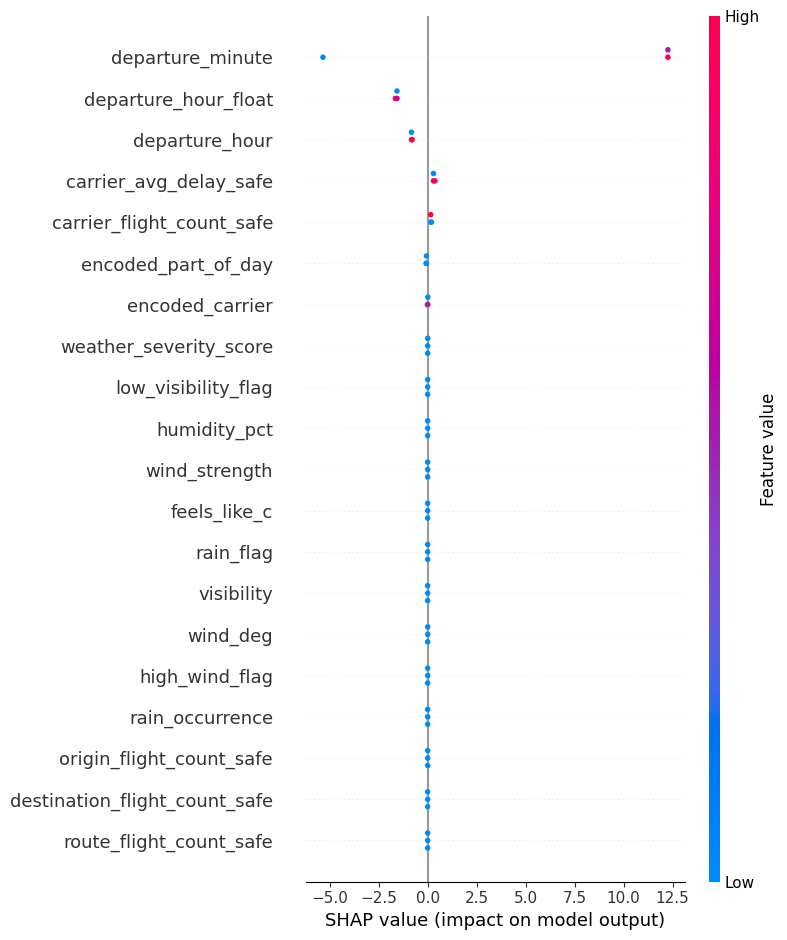


Example SHAP explanation predicted delay: 46.5 minutes


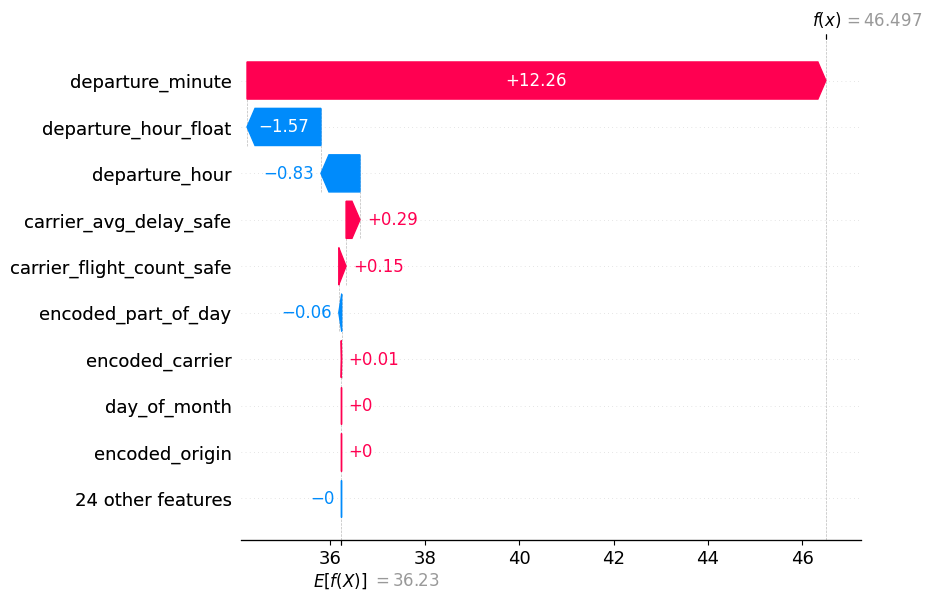

In [23]:
required_vars = ["conn"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Run the previous cells first. Missing: {missing}")

import joblib
import shap
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score, f1_score, accuracy_score

# Load saved artifacts / models
rf_model = joblib.load("aerodelay_rf_model.pkl")
log_model = joblib.load("aerodelay_log_model.pkl")
artifacts = joblib.load("aerodelay_artifacts.pkl")

model_feature_columns = artifacts["model_feature_columns"]

# Load test rows from SQLite
model_outputs = pd.read_sql("SELECT * FROM model_outputs", conn)

if model_outputs.empty:
    raise RuntimeError("model_outputs is empty. Run the Modeling cell first.")

test_df = model_outputs[model_outputs["dataset_split"] == "test"].copy()

if test_df.empty:
    raise RuntimeError("No test rows found in model_outputs.")

missing_features = [c for c in model_feature_columns if c not in test_df.columns]
if missing_features:
    raise RuntimeError(f"Missing feature columns in test set: {missing_features}")

for col in model_feature_columns:
    test_df[col] = pd.to_numeric(test_df[col], errors="coerce")

X_test = test_df[model_feature_columns].copy()
y_reg_test = pd.to_numeric(test_df["target_delay_minutes"], errors="coerce")
y_class_test = pd.to_numeric(test_df["delay_binary"], errors="coerce")

# Fill any remaining nulls using saved training medians
train_medians = artifacts["train_medians"]
for col in model_feature_columns:
    X_test[col] = X_test[col].fillna(train_medians.get(col, X_test[col].median()))

# Fresh evaluation on held-out test rows
reg_preds = rf_model.predict(X_test)
class_probs = log_model.predict_proba(X_test)[:, 1]
class_preds = log_model.predict(X_test)

rf_mae_eval = mean_absolute_error(y_reg_test, reg_preds)
rf_rmse_eval = np.sqrt(mean_squared_error(y_reg_test, reg_preds))
log_acc_eval = accuracy_score(y_class_test, class_preds)

try:
    log_auc_eval = roc_auc_score(y_class_test, class_probs)
except Exception:
    log_auc_eval = np.nan

try:
    log_f1_eval = f1_score(y_class_test, class_preds)
except Exception:
    log_f1_eval = np.nan

print("Held-out test evaluation:")
print(f"  Random Forest MAE:   {round(rf_mae_eval, 4)}")
print(f"  Random Forest RMSE:  {round(rf_rmse_eval, 4)}")
print(f"  Logistic Accuracy:   {round(log_acc_eval, 4)}")
print(f"  Logistic AUC:        {round(log_auc_eval, 4) if pd.notna(log_auc_eval) else 'N/A'}")
print(f"  Logistic F1:         {round(log_f1_eval, 4) if pd.notna(log_f1_eval) else 'N/A'}")

# Save clean evaluation summary
eval_metrics_df = pd.DataFrame([
    {"metric": "rf_mae_eval", "value": rf_mae_eval},
    {"metric": "rf_rmse_eval", "value": rf_rmse_eval},
    {"metric": "log_accuracy_eval", "value": log_acc_eval},
    {"metric": "log_auc_eval", "value": log_auc_eval},
    {"metric": "log_f1_eval", "value": log_f1_eval},
    {"metric": "test_rows_eval", "value": len(test_df)}
])

eval_metrics_df.to_sql("evaluation_metrics", conn, if_exists="replace", index=False)

# SHAP on a sample of held-out test rows
shap_sample_n = min(20, len(X_test))
X_shap = X_test.sample(n=shap_sample_n, random_state=42).copy()

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap)

# Mean absolute SHAP importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance_df = pd.DataFrame({
    "feature": model_feature_columns,
    "mean_abs_shap": mean_abs_shap
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

shap_importance_df.to_sql("shap_importance", conn, if_exists="replace", index=False)

print("\nTop SHAP features:")
display(shap_importance_df.head(10))

# SHAP summary plot
plt.figure()
shap.summary_plot(shap_values, X_shap, show=False)
plt.tight_layout()
plt.show()

example_idx = 0
example_row = X_shap.iloc[[example_idx]].copy()
example_pred = rf_model.predict(example_row)[0]

print(f"\nExample SHAP explanation predicted delay: {round(example_pred, 2)} minutes")

expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[0]

example_shap_values = shap_values[example_idx]

plt.figure()
shap.plots._waterfall.waterfall_legacy(
    expected_value,
    example_shap_values,
    feature_names=model_feature_columns,
    max_display=10
)
plt.show()

**Final Gradio App**

In [ ]:
import gradio as gr
import joblib
import shap
import requests
import numpy as np
import pandas as pd
import sqlite3

from datetime import datetime, timezone
from math import radians, cos, sin, asin, sqrt
from collections import Counter
from google.colab import userdata

AVIATION_KEY = userdata.get("AVIATIONSTACK_API_KEY")
OPENWEATHER_KEY = userdata.get("OPENWEATHER_API_KEY")
AIRPORTDB_API_TOKEN = userdata.get("AIRPORTDB_API_KEY")

if not AVIATION_KEY or not OPENWEATHER_KEY or not AIRPORTDB_API_TOKEN:
    raise ValueError(
        "Missing one or more Colab secrets: "
        "AVIATIONSTACK_API_KEY, OPENWEATHER_API_KEY, AIRPORTDB_API_KEY"
    )

rf_model = joblib.load("aerodelay_rf_model.pkl")
log_model = joblib.load("aerodelay_log_model.pkl")
artifacts = joblib.load("aerodelay_artifacts.pkl")
encoding_maps = joblib.load("aerodelay_encoding_maps.pkl")

model_feature_columns = artifacts["model_feature_columns"]
train_medians = artifacts["train_medians"]

origin_mean_map = artifacts["origin_mean_map"]
destination_mean_map = artifacts["destination_mean_map"]
route_mean_map = artifacts["route_mean_map"]
carrier_mean_map = artifacts["carrier_mean_map"]

origin_count_map = artifacts["origin_count_map"]
destination_count_map = artifacts["destination_count_map"]
route_count_map = artifacts["route_count_map"]
carrier_count_map = artifacts["carrier_count_map"]

global_train_delay_mean = artifacts["global_train_delay_mean"]

origin_map = encoding_maps.get("origin_map", {})
destination_map = encoding_maps.get("destination_map", {})
route_map = encoding_maps.get("route_map", {})
carrier_map = encoding_maps.get("carrier_map", {})
part_of_day_map = encoding_maps.get("part_of_day_map", {})

# SQLite reference data
conn_app = sqlite3.connect("aerodelay.db")

def table_exists(connection, table_name):
    q = """
    SELECT name
    FROM sqlite_master
    WHERE type='table' AND name=?
    """
    cur = connection.cursor()
    cur.execute(q, (table_name,))
    return cur.fetchone() is not None

try:
    airports_sql = pd.read_sql("SELECT * FROM airports_raw", conn_app) if table_exists(conn_app, "airports_raw") else pd.DataFrame()
except Exception:
    airports_sql = pd.DataFrame()

try:
    flights_clean_sql = pd.read_sql("SELECT * FROM flights_clean", conn_app) if table_exists(conn_app, "flights_clean") else pd.DataFrame()
except Exception:
    flights_clean_sql = pd.DataFrame()

# Full airport master table
# - use existing airport_master if already loaded
# - otherwise load from OurAirports CSV and cache in SQLite

airport_master_sql = pd.DataFrame()

try:
    if table_exists(conn_app, "airport_master"):
        airport_master_sql = pd.read_sql("SELECT * FROM airport_master", conn_app)
    else:
        airport_master_sql = pd.read_csv("https://ourairports.com/data/airports.csv")

        airport_master_sql = airport_master_sql[[
            "ident",
            "type",
            "name",
            "latitude_deg",
            "longitude_deg",
            "municipality",
            "iso_country",
            "iata_code"
        ]].copy()

        airport_master_sql["ident"] = airport_master_sql["ident"].fillna("").astype(str).str.upper().str.strip()
        airport_master_sql["iata_code"] = airport_master_sql["iata_code"].fillna("").astype(str).str.upper().str.strip()
        airport_master_sql["name"] = airport_master_sql["name"].fillna("").astype(str).str.strip()
        airport_master_sql["municipality"] = airport_master_sql["municipality"].fillna("").astype(str).str.strip()
        airport_master_sql["iso_country"] = airport_master_sql["iso_country"].fillna("").astype(str).str.upper().str.strip()

        airport_master_sql = airport_master_sql[
            airport_master_sql["type"].isin(["large_airport", "medium_airport", "small_airport"])
        ].copy()

        airport_master_sql = airport_master_sql.drop_duplicates(subset=["ident"]).reset_index(drop=True)
        airport_master_sql.to_sql("airport_master", conn_app, if_exists="replace", index=False)

except Exception as e:
    print(f"airport_master load failed: {e}")
    airport_master_sql = pd.DataFrame()

# Build display names for dropdown
if not airport_master_sql.empty:
    airport_master_sql["display_name"] = airport_master_sql.apply(
        lambda r: (
            f"{r['name']} | "
            f"IATA: {r['iata_code'] if str(r['iata_code']).strip() else 'N/A'} | "
            f"ICAO: {r['ident']} | "
            f"{r['municipality']}, {r['iso_country']}"
        ),
        axis=1
    )
else:
    print("airport_master_sql is empty, falling back to default airport choices.")

# Airport lookup helpers
DEFAULT_IATA_TO_ICAO = {
    "JFK": "KJFK",
    "LAX": "KLAX",
    "ORD": "KORD",
    "MIA": "KMIA",
    "ATL": "KATL",
    "LHR": "EGLL",
    "CDG": "LFPG",
    "MAD": "LEMD",
    "PEK": "ZBAA",
    "PKX": "ZBAD"
}

if not airports_sql.empty and {"iata_code", "icao_code"}.issubset(airports_sql.columns):
    sql_iata_to_icao = {
        str(row["iata_code"]).upper(): str(row["icao_code"]).upper()
        for _, row in airports_sql.dropna(subset=["iata_code", "icao_code"]).iterrows()
    }
else:
    sql_iata_to_icao = {}

if not airport_master_sql.empty and {"iata_code", "ident"}.issubset(airport_master_sql.columns):
    master_iata_to_icao = {
        str(row["iata_code"]).upper(): str(row["ident"]).upper()
        for _, row in airport_master_sql.iterrows()
        if str(row["iata_code"]).strip()
    }
else:
    master_iata_to_icao = {}

IATA_TO_ICAO = {**DEFAULT_IATA_TO_ICAO, **sql_iata_to_icao, **master_iata_to_icao}

def haversine_km(lat1, lon1, lat2, lon2):
    if pd.isna(lat1) or pd.isna(lon1) or pd.isna(lat2) or pd.isna(lon2):
        return np.nan
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    c = 2 * asin(sqrt(a))
    return round(6371 * c, 2)

def parse_time_to_hour_float(time_str):
    s = str(time_str).strip().upper()

    if s in ("24:00", "2400"):
        return 0.0, 0, 0

    for fmt in ("%H:%M", "%H%M", "%I:%M %p"):
        try:
            dt = datetime.strptime(s, fmt)
            hour_float = dt.hour + dt.minute / 60.0
            return hour_float, dt.hour, dt.minute
        except ValueError:
            continue

    raise ValueError("Invalid time. Use formats like 14:30, 2400, or 2:30 PM.")

def get_part_of_day(hour):
    if pd.isna(hour):
        return "unknown"
    if 5 <= hour < 12:
        return "morning"
    elif 12 <= hour < 17:
        return "afternoon"
    elif 17 <= hour < 21:
        return "evening"
    return "night"

def get_airport_row_local(iata_code):
    if airports_sql.empty:
        return None

    temp = airports_sql[airports_sql["iata_code"].astype(str).str.upper() == iata_code.upper()]
    if temp.empty:
        return None

    row = temp.iloc[0].to_dict()
    return {
        "iata_code": str(row.get("iata_code", "")).upper(),
        "icao_code": str(row.get("icao_code", "")).upper(),
        "airport_name": row.get("airport_name"),
        "latitude": pd.to_numeric(row.get("latitude"), errors="coerce"),
        "longitude": pd.to_numeric(row.get("longitude"), errors="coerce"),
        "country_code": row.get("country_code"),
        "municipality": row.get("municipality")
    }

def fetch_airport_from_airportdb(iata_or_icao_code):
    code = str(iata_or_icao_code).strip().upper()

    if len(code) == 3:
        code = IATA_TO_ICAO.get(code, code)

    url = f"https://airportdb.io/api/v1/airport/{code}"
    params = {"apiToken": AIRPORTDB_API_TOKEN}

    try:
        r = requests.get(url, params=params, timeout=12)
        r.raise_for_status()
        data = r.json()

        lat_val = data.get("latitude", data.get("lat", data.get("latitude_deg")))
        lon_val = data.get("longitude", data.get("lon", data.get("longitude_deg")))

        return {
            "iata_code": str(data.get("iata_code", "")).upper(),
            "icao_code": str(data.get("icao_code", code)).upper(),
            "airport_name": data.get("name"),
            "latitude": pd.to_numeric(lat_val, errors="coerce"),
            "longitude": pd.to_numeric(lon_val, errors="coerce"),
            "country_code": data.get("iso_country"),
            "municipality": data.get("municipality")
        }
    except Exception:
        return None

def resolve_airport_input(user_text):
    """
    Accepts:
    - full airport display string
    - IATA code (3 letters)
    - ICAO code (4 letters)
    - full/partial airport name
    """
    text_raw = str(user_text).strip()
    text = text_raw.upper()

    # First try airport_master if available
    if not airport_master_sql.empty:
        df = airport_master_sql.copy()

        exact_iata = df[df["iata_code"].astype(str).str.upper() == text]
        if not exact_iata.empty:
            return exact_iata.iloc[0].to_dict()

        exact_ident = df[df["ident"].astype(str).str.upper() == text]
        if not exact_ident.empty:
            return exact_ident.iloc[0].to_dict()

        exact_display = df[df["display_name"].astype(str).str.upper() == text]
        if not exact_display.empty:
            return exact_display.iloc[0].to_dict()

        exact_name = df[df["name"].astype(str).str.upper() == text]
        if not exact_name.empty:
            return exact_name.iloc[0].to_dict()

        partial_name = df[df["name"].astype(str).str.upper().str.contains(text, na=False)]
        if not partial_name.empty:
            return partial_name.iloc[0].to_dict()

    local_row = get_airport_row_local(text)
    if local_row is not None:
        return {
            "ident": local_row["icao_code"],
            "type": "",
            "name": local_row["airport_name"],
            "latitude_deg": local_row["latitude"],
            "longitude_deg": local_row["longitude"],
            "municipality": local_row["municipality"],
            "iso_country": local_row["country_code"],
            "iata_code": local_row["iata_code"]
        }

    db_row = fetch_airport_from_airportdb(text)
    if db_row is not None:
        return {
            "ident": db_row["icao_code"],
            "type": "",
            "name": db_row["airport_name"],
            "latitude_deg": db_row["latitude"],
            "longitude_deg": db_row["longitude"],
            "municipality": db_row["municipality"],
            "iso_country": db_row["country_code"],
            "iata_code": db_row["iata_code"]
        }

    raise ValueError(f"Could not resolve airport input: {user_text}")

# Live API helpers
def get_weather_by_coords(lat, lon):
    url = "https://api.openweathermap.org/data/2.5/weather"
    params = {
        "lat": lat,
        "lon": lon,
        "appid": OPENWEATHER_KEY,
        "units": "metric"
    }

    try:
        r = requests.get(url, params=params, timeout=15)
        r.raise_for_status()
        w = r.json()

        return {
            "temperature_c": pd.to_numeric(w.get("main", {}).get("temp"), errors="coerce"),
            "feels_like_c": pd.to_numeric(w.get("main", {}).get("feels_like"), errors="coerce"),
            "pressure_hpa": pd.to_numeric(w.get("main", {}).get("pressure"), errors="coerce"),
            "humidity_pct": pd.to_numeric(w.get("main", {}).get("humidity"), errors="coerce"),
            "wind_strength": pd.to_numeric(w.get("wind", {}).get("speed"), errors="coerce"),
            "wind_deg": pd.to_numeric(w.get("wind", {}).get("deg"), errors="coerce"),
            "visibility": pd.to_numeric(w.get("visibility"), errors="coerce"),
            "rain_occurrence": pd.to_numeric(w.get("rain", {}).get("1h", 0.0), errors="coerce"),
            "weather_main": (w.get("weather") or [{}])[0].get("main"),
            "weather_description": (w.get("weather") or [{}])[0].get("description")
        }
    except Exception:
        return {
            "temperature_c": train_medians.get("temperature_c", 15.0),
            "feels_like_c": train_medians.get("feels_like_c", 15.0),
            "pressure_hpa": train_medians.get("pressure_hpa", 1013.0),
            "humidity_pct": train_medians.get("humidity_pct", 60.0),
            "wind_strength": train_medians.get("wind_strength", 5.0),
            "wind_deg": train_medians.get("wind_deg", 180.0),
            "visibility": train_medians.get("visibility", 10000.0),
            "rain_occurrence": train_medians.get("rain_occurrence", 0.0),
            "weather_main": "UNKNOWN",
            "weather_description": "unavailable"
        }

def fetch_live_route_context(origin_iata, destination_iata):
    if not origin_iata or not destination_iata:
        return {
            "live_route_count": 0,
            "top_carrier": None,
            "statuses": []
        }

    url = "https://api.aviationstack.com/v1/flights"
    params = {
        "access_key": AVIATION_KEY,
        "dep_iata": origin_iata,
        "arr_iata": destination_iata,
        "limit": 100
    }

    try:
        r = requests.get(url, params=params, timeout=20)
        r.raise_for_status()
        payload = r.json()

        if "error" in payload:
            return {
                "live_route_count": 0,
                "top_carrier": None,
                "statuses": []
            }

        data = payload.get("data", [])
        carriers = []
        statuses = []

        for flight in data:
            airline = flight.get("airline", {}) or {}
            status = flight.get("flight_status")
            airline_iata = airline.get("iata")
            if airline_iata:
                carriers.append(str(airline_iata).upper())
            if status:
                statuses.append(status)

        top_carrier = Counter(carriers).most_common(1)[0][0] if carriers else None

        return {
            "live_route_count": len(data),
            "top_carrier": top_carrier,
            "statuses": sorted(list(set(statuses)))
        }
    except Exception:
        return {
            "live_route_count": 0,
            "top_carrier": None,
            "statuses": []
        }

# Encoding / aggregate helpers
def stable_unknown_code(value, mapping, start_offset=1000):
    if value in mapping:
        return mapping[value]
    return start_offset + (sum(ord(ch) for ch in str(value)) % 10000)

def encode_with_fallback(value, mapping, feature_name=None, start_offset=1000):
    return stable_unknown_code(value, mapping, start_offset=start_offset)

def get_safe_mean(value, mapping, distance_km=None):
    if value in mapping:
        return mapping[value]

    base = float(global_train_delay_mean)

    if distance_km is None or pd.isna(distance_km):
        return base

    median_distance = train_medians.get("estimated_path_length_km", 3500.0)
    adj = (float(distance_km) - float(median_distance)) / 2000.0
    adj = max(min(adj, 8), -8)

    return base + adj

def get_safe_count(value, mapping, live_count=None):
    if value in mapping:
        return mapping[value]

    if live_count is not None and not pd.isna(live_count):
        return max(int(live_count), 0)

    return 0

def choose_carrier(origin, destination, live_ctx, user_carrier=None):
    if user_carrier and str(user_carrier).strip():
        return str(user_carrier).strip().upper(), "user"

    if live_ctx["top_carrier"]:
        return live_ctx["top_carrier"], "aviationstack"

    if not flights_clean_sql.empty and {"route", "airline_id"}.issubset(flights_clean_sql.columns):
        route = f"{origin}_{destination}"
        subset = flights_clean_sql[flights_clean_sql["route"] == route]
        if not subset.empty:
            mode_series = subset["airline_id"].dropna().astype(str).str.upper().mode()
            if len(mode_series) > 0:
                return mode_series.iloc[0], "historical_route"

    return "UNKNOWN", "fallback"

explainer = shap.TreeExplainer(rf_model)

# Build model row
def build_prediction_row(origin, destination, scheduled_date, scheduled_time, user_carrier=None):
    origin_match = resolve_airport_input(origin)
    destination_match = resolve_airport_input(destination)

    origin_code = origin_match["iata_code"] if str(origin_match.get("iata_code", "")).strip() else str(origin_match["ident"]).upper()
    destination_code = destination_match["iata_code"] if str(destination_match.get("iata_code", "")).strip() else str(destination_match["ident"]).upper()

    origin_iata_for_api = str(origin_match.get("iata_code", "")).upper().strip()
    destination_iata_for_api = str(destination_match.get("iata_code", "")).upper().strip()

    if origin_code == destination_code:
        raise ValueError("Origin and destination must be different.")

    if scheduled_date and str(scheduled_date).strip():
        date_obj = pd.to_datetime(str(scheduled_date)).to_pydatetime()
    else:
        date_obj = datetime.now(timezone.utc)

    hour_float, hour_int, minute_int = parse_time_to_hour_float(scheduled_time)

    scheduled_dt = datetime(
        year=date_obj.year,
        month=date_obj.month,
        day=date_obj.day,
        hour=hour_int,
        minute=minute_int,
        tzinfo=timezone.utc
    )

    part_of_day = get_part_of_day(hour_int)
    route = f"{origin_code}_{destination_code}"

    origin_airport = {
        "iata_code": origin_iata_for_api,
        "icao_code": str(origin_match["ident"]).upper(),
        "airport_name": origin_match["name"],
        "latitude": pd.to_numeric(origin_match["latitude_deg"], errors="coerce"),
        "longitude": pd.to_numeric(origin_match["longitude_deg"], errors="coerce"),
        "country_code": origin_match["iso_country"],
        "municipality": origin_match["municipality"]
    }

    destination_airport = {
        "iata_code": destination_iata_for_api,
        "icao_code": str(destination_match["ident"]).upper(),
        "airport_name": destination_match["name"],
        "latitude": pd.to_numeric(destination_match["latitude_deg"], errors="coerce"),
        "longitude": pd.to_numeric(destination_match["longitude_deg"], errors="coerce"),
        "country_code": destination_match["iso_country"],
        "municipality": destination_match["municipality"]
    }

    route_distance = haversine_km(
        origin_airport["latitude"], origin_airport["longitude"],
        destination_airport["latitude"], destination_airport["longitude"]
    )

    if pd.isna(route_distance):
        if not flights_clean_sql.empty and "route" in flights_clean_sql.columns and "estimated_path_length_km" in flights_clean_sql.columns:
            subset = flights_clean_sql[flights_clean_sql["route"] == route]
            if not subset.empty:
                route_distance = pd.to_numeric(subset["estimated_path_length_km"], errors="coerce").median()

    if pd.isna(route_distance):
        route_distance = train_medians.get("estimated_path_length_km", 3500.0)

    weather = get_weather_by_coords(origin_airport["latitude"], origin_airport["longitude"])
    live_ctx = fetch_live_route_context(origin_iata_for_api, destination_iata_for_api)
    carrier, carrier_source = choose_carrier(origin_code, destination_code, live_ctx, user_carrier=user_carrier)

    encoded_origin = encode_with_fallback(origin_code, origin_map, "encoded_origin", start_offset=1000)
    encoded_destination = encode_with_fallback(destination_code, destination_map, "encoded_destination", start_offset=2000)
    encoded_route = encode_with_fallback(route, route_map, "encoded_route", start_offset=3000)
    encoded_carrier = encode_with_fallback(carrier, carrier_map, "encoded_carrier", start_offset=4000)
    encoded_part_of_day = encode_with_fallback(part_of_day, part_of_day_map, "encoded_part_of_day", start_offset=5000)

    origin_avg_delay_safe = get_safe_mean(origin_code, origin_mean_map, distance_km=route_distance)
    destination_avg_delay_safe = get_safe_mean(destination_code, destination_mean_map, distance_km=route_distance)
    route_avg_delay_safe = get_safe_mean(route, route_mean_map, distance_km=route_distance)
    carrier_avg_delay_safe = get_safe_mean(carrier, carrier_mean_map, distance_km=route_distance)

    origin_flight_count_safe = get_safe_count(origin_code, origin_count_map, live_count=live_ctx["live_route_count"])
    destination_flight_count_safe = get_safe_count(destination_code, destination_count_map, live_count=live_ctx["live_route_count"])
    route_flight_count_safe = get_safe_count(route, route_count_map, live_count=live_ctx["live_route_count"])
    carrier_flight_count_safe = get_safe_count(carrier, carrier_count_map, live_count=live_ctx["live_route_count"])

    high_wind_flag = int(float(weather["wind_strength"]) >= 10) if not pd.isna(weather["wind_strength"]) else 0
    rain_flag = int(float(weather["rain_occurrence"]) > 0) if not pd.isna(weather["rain_occurrence"]) else 0
    low_visibility_flag = int(float(weather["visibility"]) < 5000) if not pd.isna(weather["visibility"]) else 0
    weather_severity_score = high_wind_flag + rain_flag + low_visibility_flag

    feature_row = {
        "departure_hour": hour_int,
        "departure_minute": minute_int,
        "departure_hour_float": hour_float,
        "day_of_week": scheduled_dt.weekday(),
        "month": scheduled_dt.month,
        "day_of_month": scheduled_dt.day,
        "is_weekend": int(scheduled_dt.weekday() in [5, 6]),
        "encoded_origin": encoded_origin,
        "encoded_destination": encoded_destination,
        "encoded_route": encoded_route,
        "encoded_carrier": encoded_carrier,
        "encoded_part_of_day": encoded_part_of_day,
        "estimated_path_length_km": route_distance,
        "origin_avg_delay_safe": origin_avg_delay_safe,
        "destination_avg_delay_safe": destination_avg_delay_safe,
        "route_avg_delay_safe": route_avg_delay_safe,
        "carrier_avg_delay_safe": carrier_avg_delay_safe,
        "origin_flight_count_safe": origin_flight_count_safe,
        "destination_flight_count_safe": destination_flight_count_safe,
        "route_flight_count_safe": route_flight_count_safe,
        "carrier_flight_count_safe": carrier_flight_count_safe,
        "temperature_c": weather["temperature_c"],
        "feels_like_c": weather["feels_like_c"],
        "pressure_hpa": weather["pressure_hpa"],
        "humidity_pct": weather["humidity_pct"],
        "wind_strength": weather["wind_strength"],
        "wind_deg": weather["wind_deg"],
        "visibility": weather["visibility"],
        "rain_occurrence": weather["rain_occurrence"],
        "high_wind_flag": high_wind_flag,
        "rain_flag": rain_flag,
        "low_visibility_flag": low_visibility_flag,
        "weather_severity_score": weather_severity_score
    }

    final_row = {}
    for col in model_feature_columns:
        value = feature_row.get(col, train_medians.get(col, 0))
        if pd.isna(value):
            value = train_medians.get(col, 0)
        final_row[col] = value

    X_pred = pd.DataFrame([final_row])

    metadata = {
        "origin": origin_code,
        "destination": destination_code,
        "route": route,
        "carrier": carrier,
        "carrier_source": carrier_source,
        "scheduled_dt_utc": scheduled_dt,
        "origin_airport_name": origin_airport.get("airport_name", origin_code),
        "destination_airport_name": destination_airport.get("airport_name", destination_code),
        "route_distance_km": route_distance,
        "live_route_count": live_ctx["live_route_count"],
        "live_statuses": live_ctx["statuses"],
        "weather": weather
    }

    return X_pred, metadata

def debug_compare_routes():
    pek_row, _ = build_prediction_row("JFK", "PEK", "2026-04-04", "14:30", "")
    pkx_row, _ = build_prediction_row("JFK", "PKX", "2026-04-04", "14:30", "")

    compare = pd.concat(
        [
            pek_row.T.rename(columns={0: "PEK"}),
            pkx_row.T.rename(columns={0: "PKX"})
        ],
        axis=1
    )

    return compare.loc[
        [
            "encoded_destination",
            "encoded_route",
            "estimated_path_length_km",
            "destination_avg_delay_safe",
            "route_avg_delay_safe",
            "destination_flight_count_safe",
            "route_flight_count_safe",
            "encoded_carrier"
        ]
    ]

# Prediction function for Gradio
def predict_flight_delay(origin_input, destination_input, scheduled_date, scheduled_time, airline_input):
    try:
        X_pred, meta = build_prediction_row(
            origin=origin_input,
            destination=destination_input,
            scheduled_date=scheduled_date,
            scheduled_time=scheduled_time,
            user_carrier=airline_input
        )

        delay_minutes = float(rf_model.predict(X_pred)[0])
        delay_prob = float(log_model.predict_proba(X_pred)[0][1])

        delay_minutes = round(max(delay_minutes, 0), 1)

        if delay_minutes < 15:
            status = "On Time"
        elif delay_minutes < 45:
            status = "Minor Delay"
        else:
            status = "Significant Delay"

        shap_values = explainer.shap_values(X_pred)
        local_importance = pd.DataFrame({
            "feature": model_feature_columns,
            "shap_value": shap_values[0]
        })
        local_importance["abs_shap"] = local_importance["shap_value"].abs()
        local_importance = local_importance.sort_values("abs_shap", ascending=False).head(5)

        top_factors_text = "\n".join(
            [
                f"- **{row.feature}**: {round(row.shap_value, 2)}"
                for row in local_importance.itertuples(index=False)
            ]
        )

        weather = meta["weather"]
        live_statuses = ", ".join(meta["live_statuses"]) if meta["live_statuses"] else "none found"

        output = f"""
## {status}

**Predicted delay:** {delay_minutes} minutes
**Delay risk probability (>15 min):** {round(delay_prob * 100, 1)}%

**Origin:** {meta["origin"]} - {meta["origin_airport_name"]}
**Destination:** {meta["destination"]} - {meta["destination_airport_name"]}
**Scheduled departure (UTC):** {meta["scheduled_dt_utc"].strftime("%Y-%m-%d %H:%M")}
**Route distance:** {round(meta["route_distance_km"], 1)} km

**Carrier used for prediction:** {meta["carrier"]} ({meta["carrier_source"]})
**Live flights found on this route now:** {meta["live_route_count"]}
**Live route statuses seen:** {live_statuses}

### Live origin weather
- Temperature: {round(float(weather['temperature_c']), 1) if pd.notna(weather['temperature_c']) else 'N/A'} °C
- Wind: {round(float(weather['wind_strength']), 1) if pd.notna(weather['wind_strength']) else 'N/A'} m/s
- Rain (1h): {round(float(weather['rain_occurrence']), 2) if pd.notna(weather['rain_occurrence']) else 'N/A'}
- Visibility: {int(weather['visibility']) if pd.notna(weather['visibility']) else 'N/A'} m
- Condition: {weather.get('weather_main', 'UNKNOWN')} / {weather.get('weather_description', 'unavailable')}

### Top SHAP drivers
{top_factors_text}
"""
        return output

    except Exception as e:
        return f"Prediction failed: {e}"

# UI choices
if not airport_master_sql.empty and "display_name" in airport_master_sql.columns:
    airport_choices = airport_master_sql["display_name"].dropna().astype(str).tolist()
else:
    airport_choices = sorted(DEFAULT_IATA_TO_ICAO.keys())

today_utc_str = datetime.now(timezone.utc).date().isoformat()

default_origin = "John F Kennedy International Airport | IATA: JFK | ICAO: KJFK | New York, US"
default_destination = "Adolfo Suárez Madrid–Barajas Airport | IATA: MAD | ICAO: LEMD | Madrid, ES"

if airport_choices:
    if default_origin not in airport_choices:
        default_origin = airport_choices[0]
    if default_destination not in airport_choices:
        default_destination = airport_choices[1] if len(airport_choices) > 1 else airport_choices[0]

interface = gr.Interface(
    fn=predict_flight_delay,
    inputs=[
        gr.Dropdown(
            choices=airport_choices,
            value=default_origin if airport_choices else "JFK",
            allow_custom_value=True,
            label="Origin Airport (full name, IATA, or ICAO)"
        ),
        gr.Dropdown(
            choices=airport_choices,
            value=default_destination if airport_choices else "MAD",
            allow_custom_value=True,
            label="Destination Airport (full name, IATA, or ICAO)"
        ),
        gr.Textbox(
            value=today_utc_str,
            label="Scheduled Date (UTC, YYYY-MM-DD)"
        ),
        gr.Textbox(
            value="14:30",
            label="Scheduled Time (UTC, e.g. 14:30, 2400, 2:30 PM)"
        ),
        gr.Textbox(
            value="",
            label="Airline IATA (optional, e.g. AA, DL, BA)"
        )
    ],
    outputs=gr.Markdown(label="Prediction + Explanation"),
    title="AeroDelay AI - Flight Delay Predictor",
    description=(
        "Loads the saved model from your notebook, then enriches each prediction with live AirportDB, "
        "OpenWeather, and Aviationstack data. You can select a full airport name or type an IATA/ICAO code."
    ),
    examples=[
        ["John F Kennedy International Airport | IATA: JFK | ICAO: KJFK | New York, US", "Adolfo Suárez Madrid–Barajas Airport | IATA: MAD | ICAO: LEMD | Madrid, ES", today_utc_str, "14:30", ""],
        ["JFK", "PEK", today_utc_str, "14:30", ""],
        ["JFK", "PKX", today_utc_str, "14:30", ""],
        ["KJFK", "LEMD", today_utc_str, "24:00", ""],
        ["JFK", "LAX", today_utc_str, "14:30", "AA"]
    ],
    allow_flagging="never"
)

interface.launch(share=True)